# MCP Sentinel — Sprint 1: Data Exploration and Wrangling

**Project Team #2:** Sana Shaik, Shreem Dixit, Sahir Shaik, Dias Utebekov

## 1. Introduction and Sprint 1 objectives

MCP Sentinel is a security intelligence platform for Model Context Protocol (MCP) servers. Our long-term goal is to give every MCP server an explainable risk score based on its repository maintenance, its packages and dependencies, and the known vulnerabilities that affect them.

In our original Sprint 1 report we identified the data sources and proposed a data wrangling pipeline, but we had not executed it, so the profiling section still said "To be measured". This notebook documents the **executed** Sprint 1 pipeline, which covers every source and transformation that the report lists for Sprint 1. It shows:

1. how the three MCP server inventories (DeepNLP, the Official MCP Registry, and the MCPCorpus research dataset) were acquired, parsed, flattened, and profiled,
2. the measured data profile (missing values, duplicates, format inconsistencies, invalid values, category imbalance, extracted schemas),
3. the cleaning and normalization that was performed on structured data, semi-structured JSON, and unstructured text (README files, issues, release notes),
4. the results of entity resolution between the inventories and of API enrichment with GitHub, PyPI, npm, deps.dev, and OSV.dev,
5. the final processed and staging datasets that will be loaded into PostgreSQL in Sprint 2.

The ETL logic lives in `src/etl.py`, `src/sources.py`, and `src/profiling.py` and is run with `python scripts/run_sprint1.py`. This notebook does not duplicate that code. It imports a few functions to show the raw data and otherwise reads the files that the pipeline exported, so every table and chart below reflects the actual pipeline output.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src import etl, profiling, sources

RAW = PROJECT_ROOT / "data" / "raw"
STAGING = PROJECT_ROOT / "data" / "staging"
PROCESSED = PROJECT_ROOT / "data" / "processed"
REPORTS = PROJECT_ROOT / "reports"

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

SURFACE, INK, SECONDARY, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": SECONDARY, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": SECONDARY, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titlelocation": "left",
})


def horizontal_bars(series, title, xlabel):
    figure, axis = plt.subplots(figsize=(8, 0.42 * len(series) + 1.3))
    bars = axis.barh(series.index[::-1], series.values[::-1], color=BLUE, height=0.62, edgecolor=SURFACE, linewidth=1)
    axis.bar_label(bars, padding=3, color=SECONDARY, fontsize=9)
    axis.set_title(title, color=INK)
    axis.set_xlabel(xlabel)
    axis.grid(axis="y", visible=False)
    axis.margins(x=0.12)
    plt.tight_layout()
    plt.show()

## 2. Data sources

These are the sources listed in the Data Source Inventory and the pipeline diagram of our Sprint 1 report.

| Source | Role in MCP Sentinel | Access method |
|---|---|---|
| **DeepNLP MCP Servers** (Hugging Face) | Initial MCP server inventory: name, publisher id, website, description, category, Bing rank, snapshot month | Hugging Face Hub API and file download |
| **Official MCP Registry** | Second inventory: each server's declared packages, versions, repository, and subfolder | `/v0/servers?version=latest`, paginated |
| **MCPCorpus** (research dataset, "A Large-Scale Evolvable Dataset for MCP Ecosystem and Security Analysis") | Large research inventory with categories, tags, and tool definitions | Raw data file from the GitHub repository at a pinned commit |
| **GitHub REST API** | Repository maintenance and popularity (stars, forks, issues, archived status, dates, commits, contributors, releases), package manifests, and text documents | `/repos/...` endpoints with `GITHUB_TOKEN` |
| **PyPI JSON API** | Python package identity, versions, project URLs, dependencies | `https://pypi.org/pypi/<name>/json` |
| **npm registry** | JavaScript/TypeScript package identity, versions, repository link, dependencies | `https://registry.npmjs.org/<name>` |
| **deps.dev** | Resolved dependency graph (direct and indirect dependencies with exact versions) | `/v3/systems/<eco>/packages/<name>/versions/<v>:dependencies` |
| **OSV.dev** | Vulnerability intelligence for a specific package version | `/v1/querybatch` and `/v1/vulns/<id>` |

DeepNLP is the starting inventory that is enriched in depth. The MCP Registry and MCPCorpus are profiled as inventories of their own and linked to the DeepNLP servers by repository. GitHub tells us where the code lives and whether it is maintained, the package registries tell us which published package corresponds to the server, deps.dev tells us which exact dependency versions that package pulls in, and OSV.dev tells us which of those versions have known vulnerabilities.

All three inventories are preserved in `data/raw/` together with metadata files that record where and when they were obtained and a SHA-256 checksum, so every transformation can be traced back to the original data.

In [2]:
metadata = json.loads((RAW / "deepnlp_source_metadata.json").read_text(encoding="utf-8"))
snapshots = []
for name in ["deepnlp", "mcp_registry_servers", "mcpcorpus_servers"]:
    info = json.loads((RAW / f"{name}_source_metadata.json").read_text(encoding="utf-8"))
    snapshots.append({
        "snapshot": name, "source_url": info["source_url"], "version": info.get("revision") or info.get("commit") or info.get("query"),
        "downloaded_at": info["downloaded_at"], "sha256": (info.get("sha256") or info["files"][0]["sha256"])[:16],
    })
pd.DataFrame(snapshots)

,snapshot,source_url,version,downloaded_at,sha256
0,deepnlp,https://huggingface.co/datasets/DeepNLP/mcp-servers,f1bb6287a9e200f8cdcc0079718573515a74754e,2026-10-18T06:25:46Z,7afdae8d397d9141
1,mcp_registry_servers,https://registry.modelcontextprotocol.io/v0/servers,version=latest,2026-10-18T07:22:01Z,49e91c018ed95b1d
2,mcpcorpus_servers,https://github.com/Snakinya/MCPCorpus,295fe37cd972ea9aa1b48578b2d7bcc40a72ee12,2026-10-18T07:22:04Z,cc14fc4fe5c68b73


## 3. Loading the inventories

Before parsing, we inspected each file format. Although the DeepNLP file has a `.json` extension, it is **JSON Lines** (one JSON object per line), not a single JSON array. The loader in `src/etl.py` therefore uses `json.JSONDecoder.raw_decode` in a loop, which handles JSON Lines, concatenated JSON objects, and plain JSON arrays, and counts malformed records instead of crashing. The first two raw lines look like this:

In [3]:
raw_lines = (RAW / metadata["files"][0]["file_name"]).read_text(encoding="utf-8").splitlines()
print(f"Lines in file: {len(raw_lines)}")
for line in raw_lines[:2]:
    print(line)

Lines in file: 296
{"content_name": "AgentRPC", "publisher_id": "pub-agentrpc", "website": "https://www.agentrpc.com/", "statistic": {"Bing Rank": 50.0}, "subfield": "MCP SERVER", "field": "AI AGENT", "description": "\u2197 Toggle menu Node.js Go Python OpenAI Anthropic Groq Cerebras OpenRouter LiteLLM > import  { AgentRPC }  from  'agentrpc' ;   import  { z }  from  'zod' ;    const rpc =  new  AgentRPC ( {  apiSecret", "month": "202503", "content": ""}
{"content_name": "Git", "publisher_id": "pub-git", "website": "https://github.com/modelcontextprotocol/servers/tree/main/src/git", "statistic": {"Bing Rank": 50.0}, "subfield": "MCP SERVER", "field": "AI AGENT", "description": " - Tools to read, search, and manipulate Git repositories", "month": "202503", "content": ""}


In [4]:
records, malformed = etl.load_deepnlp_records(metadata)
raw_frame = etl.flatten_records(records)
print(f"Records parsed: {len(records)}")
print(f"Malformed records: {malformed}")
print(f"Flattened table: {raw_frame.shape[0]} rows x {raw_frame.shape[1]} columns")
raw_frame.head()

Records parsed: 296
Malformed records: 0
Flattened table: 296 rows x 11 columns


,content_name,publisher_id,website,subfield,field,description,month,content,source_file,source_record_number,statistic_bing_rank
0,AgentRPC,pub-agentrpc,https://www.agentrpc.com/,MCP SERVER,AI AGENT,↗ Toggle menu Node.js Go Python OpenAI Anthropic Groq Cerebras OpenRouter LiteLLM > im...,202503,,data_agent_mcp-server_202503.json,1,50.0
1,Git,pub-git,https://github.com/modelcontextprotocol/servers/tree/main/src/git,MCP SERVER,AI AGENT,"- Tools to read, search, and manipulate Git repositories",202503,,data_agent_mcp-server_202503.json,2,50.0
2,Actors MCP Server,pub-actors-mcp-server,https://apify.com/apify/actors-mcp-server,MCP SERVER,AI AGENT,": Use 3,000+ pre-built cloud tools to extract data from websites, e-commerce, social m...",202503,,data_agent_mcp-server_202503.json,3,50.0
3,ArangoDB,pub-arangodb,https://arangodb.com/,MCP SERVER,AI AGENT,"Enable JavaScript and cookies to continue 正在验证您是否是真人。这可能需要几秒钟时间。,.",202503,,data_agent_mcp-server_202503.json,4,50.0
4,Anki,pub-anki,https://apps.ankiweb.net,MCP SERVER,AI AGENT,Anki Anki The single biggest change that Anki brings about is that it means memory is ...,202503,,data_agent_mcp-server_202503.json,5,50.0


The Official MCP Registry is a paginated JSON API: each page holds up to 100 entries and a cursor to the next page. Each entry wraps the server definition and registry metadata in nested objects. MCPCorpus is a single JSON array. Both snapshots are stored gzip-compressed.

In [5]:
registry_entries, registry_metadata = sources.read_raw_snapshot("mcp_registry_servers")
corpus_records, corpus_metadata = sources.read_raw_snapshot("mcpcorpus_servers")
print(f"MCP Registry entries: {len(registry_entries)} from {registry_metadata['pages']} pages")
print(f"MCPCorpus records: {len(corpus_records)} (commit {corpus_metadata['commit'][:12]})")
example = next(entry for entry in registry_entries if entry["server"].get("packages") and entry["server"].get("repository"))
print(json.dumps(example, indent=1)[:1200])

MCP Registry entries: 45657 from 457 pages
MCPCorpus records: 13875 (commit 295fe37cd972)
{
 "server": {
  "$schema": "https://static.modelcontextprotocol.io/schemas/2025-12-11/server.schema.json",
  "name": "ai.adeu/adeu",
  "description": "Automated DOCX Redlining Engine",
  "repository": {
   "url": "https://github.com/dealfluence/adeu",
   "source": "github"
  },
  "version": "1.7.1",
  "packages": [
   {
    "registryType": "npm",
    "identifier": "@adeu/mcp-server",
    "version": "1.7.1",
    "transport": {
     "type": "stdio"
    }
   }
  ]
 },
 "_meta": {
  "io.modelcontextprotocol.registry/official": {
   "status": "active",
   "statusChangedAt": "2026-05-16T13:54:48.18266Z",
   "publishedAt": "2026-05-16T13:54:48.18266Z",
   "updatedAt": "2026-05-16T13:54:48.18266Z",
   "isLatest": true
  }
 }
}


## 4. Dataset structure and initial exploration

Our original report expected 296 records and eight major attributes. The real DeepNLP file confirms **296 records**, but it actually has **nine source attributes**: besides `content_name`, `publisher_id`, `website`, `description`, `field`, `subfield`, `statistic`, and `month`, there is also a `content` attribute. The category attribute is called `subfield`, not `sub_field`. Two provenance columns (`source_file`, `source_record_number`) were added by the loader.

In [6]:
structure = pd.DataFrame({
    "dtype": raw_frame.dtypes.astype(str),
    "non_null": raw_frame.notna().sum(),
    "empty_strings": raw_frame.apply(lambda column: column.map(lambda value: isinstance(value, str) and not value.strip()).sum()),
    "distinct_values": raw_frame.astype(str).nunique(),
})
structure

,dtype,non_null,empty_strings,distinct_values
content_name,str,296,0,296
publisher_id,str,296,0,296
website,str,296,0,296
subfield,str,296,0,1
field,str,296,0,1
description,str,296,1,289
month,str,296,0,1
content,str,296,296,1
source_file,str,296,0,1
source_record_number,int64,296,0,296


Several DeepNLP attributes carry almost no information. `field`, `subfield`, and `month` have a single value across the whole dataset, so DeepNLP has no real category information and is one snapshot rather than a time series. The more informative view is *where* the `website` field points, because that determines whether a server can be enriched at all.

In [7]:
for column in ["field", "subfield", "month"]:
    print(column, raw_frame[column].value_counts().to_dict())

servers = pd.read_csv(STAGING / "mcp_servers.csv")
display(servers["github_url_type"].value_counts().rename("servers").to_frame())
servers["website_host"].value_counts().head(10).rename("servers").to_frame()

field {'AI AGENT': 296}
subfield {'MCP SERVER': 296}
month {'202503': 296}


,servers
github_url_type,
repository,214
not_github,50
repository_subpath,31
owner_only,1


,servers
website_host,
github.com,246
apify.com,2
agentrpc.com,1
arangodb.com,1
apps.ankiweb.net,1
descope.com,1
lingo.dev,1
open-rpc.org,1
apimatic.io,1


### 4.1 Schema extraction

Our report lists *schema extraction* as a semi-structured transformation. The pipeline walks every raw JSON record of each inventory and records each field path (nested objects with `.`, array items with `[]`), the value types seen, and how many records contain it. Paths with more than one value type reveal format inconsistencies before any cleaning is done.

In [8]:
schemas = pd.read_csv(REPORTS / "source_schemas.csv")
display(schemas.groupby("source").agg(
    field_paths=("field_path", "size"),
    mixed_type_paths=("value_types", lambda v: v.str.contains(";").sum()),
    nested_paths=("field_path", lambda v: v.str.contains(r"\.|\[\]").sum()),
))
schemas[schemas["value_types"].str.contains(";")].sort_values(["source", "record_coverage_pct"], ascending=[True, False]).head(15)

,field_paths,mixed_type_paths,nested_paths
source,,,
deepnlp,10,0,1
mcpcorpus,178,13,164
official_mcp_registry,7646,127,7644


,source,field_path,value_types,records_with_field,record_coverage_pct
7656,mcpcorpus,author_name,null; str,13875,100.00
7657,mcpcorpus,category,null; str,13875,100.00
7658,mcpcorpus,description,null; str,13875,100.00
7659,mcpcorpus,github,dict; null,13875,100.00
7826,mcpcorpus,server_command,null; str,13875,100.00
7827,mcpcorpus,server_config,null; str,13875,100.00
7828,mcpcorpus,sse_url,null; str,13875,100.00
7829,mcpcorpus,tags,null; str,13875,100.00
7831,mcpcorpus,tools,null; str,13875,100.00
7832,mcpcorpus,type,null; str,13875,100.00


The schema shows, for example, that MCPCorpus stores `tags` and `tools` either as text or as null, that the `github` object is either a nested object or null, and that `github.languages` produces one field path per programming language. In the MCP Registry, optional fields such as `repository.subfolder` or `packages[].environmentVariables` appear only in some entries.

### 4.2 Category distribution and data imbalance

DeepNLP's category fields are constant, so the "data imbalance" issue from our report could not be measured there. MCPCorpus does have a category attribute:

Categories: 25; records: 13873
Share of the two largest categories: 86.12%


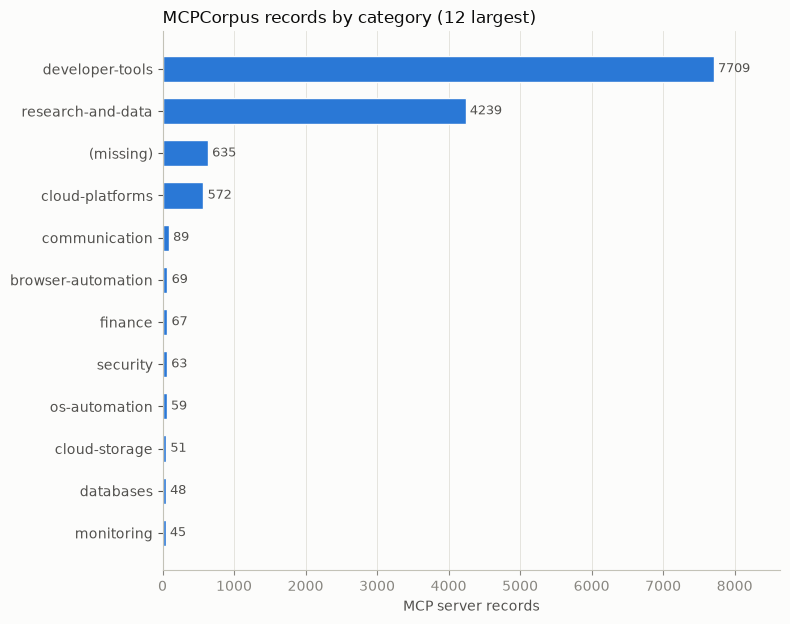

In [9]:
corpus = pd.read_csv(STAGING / "mcpcorpus_servers.csv")
category_counts = corpus["category"].fillna("(missing)").value_counts()
print(f"Categories: {corpus['category'].nunique()}; records: {len(corpus)}")
print(f"Share of the two largest categories: {round(100 * category_counts.head(2).sum() / len(corpus), 2)}%")
horizontal_bars(category_counts.head(12), "MCPCorpus records by category (12 largest)", "MCP server records")

**Interpretation.** The category distribution is extremely imbalanced: two categories (`developer-tools` and `research-and-data`) contain most of the records, and many categories have only a handful of servers. Any later classifier that uses categories would need to account for this imbalance, as our report anticipated.

## 5. Missing-value analysis

Missing values were measured for DeepNLP **before cleaning** on the flattened raw table and **after cleaning** on the staged `mcp_servers` table. In the raw data, missing information mostly does not appear as real nulls but as empty strings (`content`, some descriptions) or as empty nested objects (`statistic: {}`), which a simple `isna()` would not detect. The profile therefore counts both true nulls and blank or placeholder strings (`""`, `"N/A"`, `"null"`, `"unknown"`, ...). After cleaning, every placeholder has been converted to a real null.

In [10]:
missing_values = pd.read_csv(REPORTS / "missing_values.csv")
before = missing_values[(missing_values["dataset"] == "deepnlp") & (missing_values["stage"] == "before_cleaning")]
after = missing_values[(missing_values["dataset"] == "deepnlp") & (missing_values["stage"] == "after_cleaning")]
before[["column", "dtype", "null_count", "blank_or_placeholder_count", "missing_count", "missing_pct"]]

,column,dtype,null_count,blank_or_placeholder_count,missing_count,missing_pct
0,content_name,str,0,0,0,0.00
1,publisher_id,str,0,0,0,0.00
2,website,str,0,0,0,0.00
3,subfield,str,0,0,0,0.00
4,field,str,0,0,0,0.00
5,description,str,0,1,1,0.34
6,month,str,0,0,0,0.00
7,content,str,0,296,296,100.00
8,source_file,str,0,0,0,0.00
9,source_record_number,int64,0,0,0,0.00


In [11]:
comparison = profiling.missing_comparison(before, after)
comparison

,source_column,staging_column,missing_before,missing_before_pct,missing_after,missing_after_pct
0,content_name,server_name,0,0.00,0,0.00
1,publisher_id,publisher_id,0,0.00,0,0.00
2,website,website_url,0,0.00,0,0.00
3,subfield,sub_field,0,0.00,0,0.00
4,field,field,0,0.00,0,0.00
5,description,description,1,0.34,9,3.04
6,month,snapshot_month,0,0.00,0,0.00
7,content,(dropped),296,100.00,<NA>,NaN
8,source_file,source_file,0,0.00,0,0.00
9,source_record_number,source_record_number,0,0.00,0,0.00


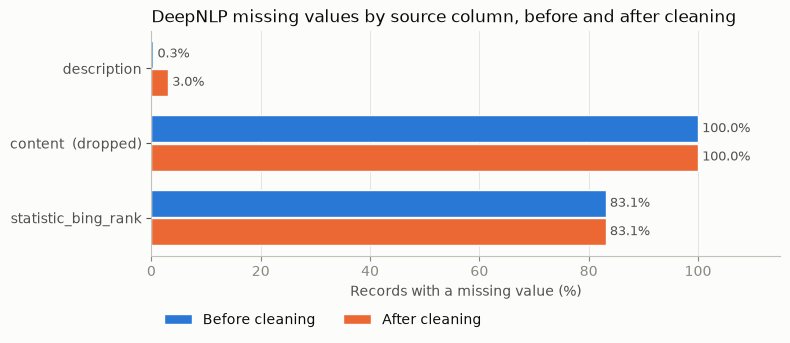

In [12]:
chart = comparison[(comparison["missing_before_pct"] > 0) | (comparison["missing_after_pct"].fillna(0) > 0)].copy()
chart["missing_after_pct"] = chart["missing_after_pct"].fillna(100.0)
labels = chart["source_column"] + chart["staging_column"].map(lambda name: "  (dropped)" if name == "(dropped)" else "")
positions = range(len(chart))
figure, axis = plt.subplots(figsize=(8, 0.75 * len(chart) + 1.4))
before_bars = axis.barh([p - 0.19 for p in positions], chart["missing_before_pct"], height=0.36, color=BLUE, edgecolor=SURFACE, linewidth=1, label="Before cleaning")
after_bars = axis.barh([p + 0.19 for p in positions], chart["missing_after_pct"], height=0.36, color=ORANGE, edgecolor=SURFACE, linewidth=1, label="After cleaning")
axis.bar_label(before_bars, fmt="%.1f%%", padding=3, color=SECONDARY, fontsize=9)
axis.bar_label(after_bars, fmt="%.1f%%", padding=3, color=SECONDARY, fontsize=9)
axis.set_yticks(list(positions), labels)
axis.invert_yaxis()
axis.set_xlim(0, 115)
axis.set_xlabel("Records with a missing value (%)")
axis.set_title("DeepNLP missing values by source column, before and after cleaning", color=INK)
axis.grid(axis="y", visible=False)
axis.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2)
plt.tight_layout()
plt.show()

**Interpretation.** `content` is empty in every record, so it was dropped from the staging table (its "after" bar is shown at 100% for that reason). `statistic_bing_rank` is missing for most records because only a minority of records have a non-empty `statistic` object. `description` gains a few missing values after cleaning: these were descriptions that consisted only of punctuation (for example `"."` or `")."`) and became empty once leading list markers were stripped. The identifying attributes (`content_name`, `publisher_id`, `website`) are complete.

The other two inventories were profiled the same way after cleaning. The columns with the most missing values are:

In [13]:
others = missing_values[(missing_values["dataset"] != "deepnlp") & (missing_values["missing_count"] > 0)]
others.sort_values(["dataset", "missing_pct"], ascending=[True, False]).groupby("dataset").head(6)[["dataset", "column", "missing_count", "missing_pct"]]

,dataset,column,missing_count,missing_pct
79,mcpcorpus,tool_count,13818,99.60
80,mcpcorpus,tool_names,13818,99.60
85,mcpcorpus,github_subpath,13794,99.43
76,mcpcorpus,record_type,12975,93.53
93,mcpcorpus,license,7010,50.53
77,mcpcorpus,tags,5089,36.68
48,official_mcp_registry,repository_subfolder,42676,93.47
44,official_mcp_registry,website_url,19226,42.11
41,official_mcp_registry,title,14526,31.82
47,official_mcp_registry,repository_id,13787,30.20


## 6. Duplicate detection

Duplicates were checked within each inventory (exact duplicate records, duplicated identifiers, duplicated website strings before and after URL normalization, duplicated repository locations, possible *semantic* duplicates) and **across** inventories (the same server listed in DeepNLP, the MCP Registry, and MCPCorpus).

In [14]:
pd.read_csv(REPORTS / "duplicate_summary.csv")

,dataset,check,count,description
0,deepnlp,exact_duplicate_records,0,Raw records identical to an earlier record in every source field
1,deepnlp,duplicate_publisher_id,0,Records repeating an earlier publisher_id
2,deepnlp,duplicate_server_name,0,Records repeating an earlier content_name exactly
3,deepnlp,duplicate_server_name_case_insensitive,0,Records repeating an earlier content_name after trimming and lowercasing
4,deepnlp,duplicate_website_raw,0,Records repeating an earlier website string exactly
5,deepnlp,duplicate_website_normalized,0,Records repeating an earlier website after URL normalization
6,deepnlp,duplicate_server_id,0,Staged records repeating a server_id (must be 0)
7,deepnlp,duplicate_repository_location,0,Servers pointing to the same repository and the same subdirectory
8,deepnlp,servers_sharing_a_repository,19,Servers whose GitHub repository is shared with at least one other server (monorepo pat...
9,deepnlp,repositories_shared_by_multiple_servers,1,Distinct repositories referenced by more than one server


DeepNLP has no exact duplicates and no repeated identifiers, so no DeepNLP records had to be removed. MCPCorpus, on the other hand, lists many repositories more than once. Inside DeepNLP the more interesting result is **entity resolution**: many servers share one GitHub repository. These are not duplicates. In the `modelcontextprotocol/servers` monorepo, for example, every subdirectory is an independent server with its own package, so they keep separate `server_id` values and only share the `repository_id`.

In [15]:
shared = servers.dropna(subset=["repository_id"])
shared = shared[shared["repository_id"].duplicated(keep=False)]
display(shared.groupby("repository_id").size().rename("servers").to_frame())
shared[["server_id", "server_name", "repository_id", "github_subpath"]].head(10)

,servers
repository_id,
github:modelcontextprotocol/servers,19


,server_id,server_name,repository_id,github_subpath
1,deepnlp:pub-git,Git,github:modelcontextprotocol/servers,src/git
6,deepnlp:pub-aws-kb-retrieval,AWS KB Retrieval,github:modelcontextprotocol/servers,src/aws-kb-retrieval-server
37,deepnlp:pub-gitlab,GitLab,github:modelcontextprotocol/servers,src/gitlab
49,deepnlp:pub-redis,Redis,github:modelcontextprotocol/servers,src/redis
62,deepnlp:pub-google-maps,Google Maps,github:modelcontextprotocol/servers,src/google-maps
64,deepnlp:pub-everything,Everything,github:modelcontextprotocol/servers,src/everything
84,deepnlp:pub-brave-search,Brave Search,github:modelcontextprotocol/servers,src/brave-search
85,deepnlp:pub-github,GitHub,github:modelcontextprotocol/servers,src/github
109,deepnlp:pub-postgresql,PostgreSQL,github:modelcontextprotocol/servers,src/postgres
117,deepnlp:pub-everart,EverArt,github:modelcontextprotocol/servers,src/everart


The name-based check flags a small number of possible semantic duplicates. Looking at them manually shows they are different implementations hosted in different repositories (for example two independent MSSQL servers), so they are **flagged for review, not merged**.

In [16]:
servers.loc[servers["possible_duplicate_group"].notna(), ["possible_duplicate_group", "server_name", "website_url"]]

,possible_duplicate_group,server_name,website_url
97,name:mssql,MSSQL,https://github.com/aekanun2020/mcp-server/
209,name:xero,Xero-mcp-server,https://github.com/john-zhang-dev/xero-mcp
286,name:xero,Xero,https://github.com/XeroAPI/xero-mcp-server
293,name:mssql,MSSQL-MCP,https://github.com/daobataotie/mssql-mcp


Across inventories, a DeepNLP server is linked to an MCP Registry entry or MCPCorpus record only when the normalized repository id (or the repository's current name after a rename) **and** the subdirectory are equal. A server that matches more than one record is marked `multiple_matches` and is not used to infer anything.

In [17]:
server_source_map = pd.read_csv(STAGING / "server_source_map.csv")
display(pd.crosstab(server_source_map["linked_source"], server_source_map["match_status"]))
print("DeepNLP servers with at least one link:", server_source_map["server_id"].nunique(), "of", len(servers))

match_status,matched,multiple_matches
linked_source,,
mcpcorpus,166,61
official_mcp_registry,18,6


DeepNLP servers with at least one link: 195 of 296


## 7. Data quality issues

The table below lists every quality issue that the profiling script measured, the number of affected records, and how it was handled.

In [18]:
pd.read_csv(REPORTS / "data_quality_issues.csv")

,dataset,issue,affected_records,pct_of_records,issue_type,handling
0,deepnlp,website_trailing_slash,26,8.78,Format inconsistency,Trailing slash removed in website_normalized
1,deepnlp,website_http_not_https,1,0.34,Format inconsistency,Flagged; original scheme kept because an HTTPS upgrade was not verified
2,deepnlp,website_url_fragment,2,0.68,Format inconsistency,Fragment removed in website_normalized
3,deepnlp,website_invalid_url,0,0.00,Invalid value,Flagged in website_is_valid; record retained
4,deepnlp,website_not_github,50,16.89,Missing repository reference,No repository identified; record retained and marked not_assessed
5,deepnlp,github_url_with_subdirectory,31,10.47,Format inconsistency,"Owner, repository, ref and subpath parsed into separate columns"
6,deepnlp,github_owner_only_url,1,0.34,Ambiguous reference,Not mapped to any repository
7,deepnlp,description_starts_with_list_marker,222,75.00,Format inconsistency,Stripped together with other leading punctuation (see strip_leading_list_markers in th...
8,deepnlp,description_surrounding_whitespace,250,84.46,Format inconsistency,Whitespace trimmed
9,deepnlp,description_repeated_internal_whitespace,23,7.77,Format inconsistency,Repeated whitespace collapsed


The most widespread DeepNLP issue is in the `description` attribute. The descriptions were scraped from a markdown list and from product websites, so most of them start with a list marker (`" - "`), and the descriptions of non-GitHub servers often contain website navigation or cookie-banner text instead of a real description. The pipeline keeps the original text and adds a `description_quality` flag:

In [19]:
display(servers["description_quality"].value_counts().rename("servers").to_frame())
servers.loc[servers["description_quality"].isin(["web_boilerplate", "fragment"]), ["server_name", "description_quality", "description_original"]].head(8)

,servers
description_quality,
ok,253
fragment,21
missing,9
web_boilerplate,8
too_short,5


,server_name,description_quality,description_original
0,AgentRPC,web_boilerplate,↗ Toggle menu Node.js Go Python OpenAI Anthropic Groq Cerebras OpenRouter LiteLLM > im...
2,Actors MCP Server,fragment,": Use 3,000+ pre-built cloud tools to extract data from websites, e-commerce, social m..."
3,ArangoDB,web_boilerplate,"Enable JavaScript and cookies to continue 正在验证您是否是真人。这可能需要几秒钟时间。,."
5,Descope,web_boilerplate,Skip to main content Log In Sign up Book a demo CIAM | CIAMC CIAM C | Sign up Speak wi...
7,Lingo.dev,fragment,zh Mistral AI Mistral AI AI 本地化引擎 Git 原生 UI 本地化 动态内容的 API 和 SDK 可组合...
9,APIMatic,fragment,. The server processes OpenAPI files and returns validation summaries by leveraging AP...
10,gotoHuman,fragment,"pip npm never shared restricted European GDPR and CCPA/CPRA SOC 3 and ISO 27001, inbox."
15,Aiven projects,web_boilerplate,Skip to content Platform Solutions Resources Company Pricing Change language Platform ...


Some server names are not names at all but link text that was captured by the scraper (for example "here" or "more"). They are flagged with `server_name_is_generic` rather than deleted, because the website and publisher id are still valid.

In [20]:
servers.loc[servers["server_name_is_generic"], ["server_id", "server_name", "website_url"]]

,server_id,server_name,website_url
108,deepnlp:pub-demo-video,demo video,https://www.youtube.com/watch?v=WuVOmYLRFmI&feature=youtu.be
254,deepnlp:pub-here,here,https://devrev.ai/docs/import#available-sources
257,deepnlp:pub-more,more,https://github.com/quarkiverse/quarkus-mcp-servers/tree/main/jdbc#supported-jdbc-variants


MCPCorpus has a different kind of quality problem: some values are stored in inconsistent formats. Tags are sometimes JSON array text and sometimes comma-separated text, tool definitions are JSON text inside a string field, and the nested `github.languages` object uses language names as keys, so it has a different shape in almost every record.

In [21]:
display(corpus["tag_format"].value_counts().rename("records").to_frame())
display(corpus["tool_format"].value_counts().rename("records").to_frame())
corpus[["corpus_id", "tags", "tag_format", "stars", "archived", "tool_count"]].dropna(subset=["tags"]).head(5)

,records
tag_format,
comma_separated,8784
json_array,4850
empty,236
invalid_json,3


,records
tool_format,
missing,13688
invalid_json,130
json_array,55


,corpus_id,tags,tag_format,stars,archived,tool_count
1,mcpcorpus:3087,time; timezone; mcp-server,comma_separated,51119.0,False,2.0
3,mcpcorpus:13520,search; search-api,comma_separated,NaN,NaN,1.0
6,mcpcorpus:10002,mcp; llm; mcp-server; vibe-coding,comma_separated,10600.0,False,NaN
7,mcpcorpus:7801,text-to-speech; mcp; image-generation; text-to-image; video-generation; image-to-video...,comma_separated,528.0,False,NaN
8,mcpcorpus:7041,mcp; google-search; google-search-api; serper; serperdev; mcp-server; serperapi; googl...,comma_separated,3.0,False,NaN


## 8. Cleaning and normalization

The cleaning steps were designed to be **non-destructive**: original DeepNLP values are kept in `website_original` and `description_original`, nothing is imputed, and incomplete records are retained and labelled instead of dropped. Every step and the number of affected records is logged in `reports/cleaning_log.csv`:

In [22]:
pd.read_csv(REPORTS / "cleaning_log.csv")

,dataset,step,column,records_affected,action
0,deepnlp,normalize_whitespace,server_name,0,modified
1,deepnlp,placeholder_to_null,server_name,0,modified
2,deepnlp,normalize_whitespace,publisher_id,0,modified
3,deepnlp,placeholder_to_null,publisher_id,0,modified
4,deepnlp,normalize_whitespace,website_url,0,modified
...,...,...,...,...,...
63,mcpcorpus,parse_mixed_format_tags,tags,13637,modified
64,mcpcorpus,parse_json_string_tools,tools,55,modified
65,mcpcorpus,cast_to_nullable_integer_and_boolean,github_*,13002,modified
66,mcpcorpus,extract_github_reference,url,13866,modified


Examples of URL normalization: the host is lowercased, `www.` is removed, trailing slashes and fragments are dropped, and GitHub URLs are split into owner, repository, branch, and subdirectory. A stable `repository_id` (`github:<owner>/<repo>`) is created for joining across sources.

In [23]:
changed = servers[servers["website_original"].str.rstrip("/") != servers["website_normalized"]]
display(changed[["website_original", "website_normalized"]].head(6))
servers.loc[servers["github_url_type"] != "repository", ["website_url", "github_url_type", "github_owner", "github_repo", "github_ref", "github_subpath"]].drop_duplicates("github_url_type")

,website_original,website_normalized
0,https://www.agentrpc.com/,https://agentrpc.com
9,https://www.apimatic.io/,https://apimatic.io
10,https://www.gotohuman.com,https://gotohuman.com
11,https://www.adfin.com/,https://adfin.com
16,https://www.holaspirit.com/,https://holaspirit.com
17,https://www.agentql.com/,https://agentql.com


,website_url,github_url_type,github_owner,github_repo,github_ref,github_subpath
0,https://www.agentrpc.com/,not_github,NaN,NaN,NaN,NaN
1,https://github.com/modelcontextprotocol/servers/tree/main/src/git,repository_subpath,modelcontextprotocol,servers,main,src/git
246,https://github.com/opentoolsteam,owner_only,opentoolsteam,NaN,NaN,NaN


In [24]:
servers[["description_original", "description"]].head(5)

,description_original,description
0,↗ Toggle menu Node.js Go Python OpenAI Anthropic Groq Cerebras OpenRouter LiteLLM > im...,Toggle menu Node.js Go Python OpenAI Anthropic Groq Cerebras OpenRouter LiteLLM > impo...
1,"- Tools to read, search, and manipulate Git repositories","Tools to read, search, and manipulate Git repositories"
2,": Use 3,000+ pre-built cloud tools to extract data from websites, e-commerce, social m...","Use 3,000+ pre-built cloud tools to extract data from websites, e-commerce, social med..."
3,"Enable JavaScript and cookies to continue 正在验证您是否是真人。这可能需要几秒钟时间。,.","Enable JavaScript and cookies to continue 正在验证您是否是真人。这可能需要几秒钟时间。,."
4,Anki Anki The single biggest change that Anki brings about is that it means memory is ...,Anki Anki The single biggest change that Anki brings about is that it means memory is ...


### 8.1 Unstructured text: README files, release notes, and issues

Our report lists text cleaning, metadata generation, and document filtering for README files, repository issues, and release notes. For every mapped server location the pipeline downloaded the README; for every repository it downloaded the latest release notes and the ten most recently updated issues.

- **Text cleaning** removed HTML tags and comments, badge images, image and link markup (link text is kept), markdown headings, list and table syntax, and extra whitespace. Code and configuration text was kept on purpose, because environment variable names, commands, and API names are potential security signals.
- **Metadata generation** stored the document type, server or repository id, title, source URL, publication date, collection time, and length before and after cleaning with each document.
- **Document filtering** removed pull requests (the GitHub issues endpoint also returns them), bot-authored issues, READMEs that do not exist, and documents that are empty or shorter than 20 characters after cleaning.

All of this text is untrusted data: it is stored for later analysis, never executed or followed.

In [25]:
documents = pd.read_csv(STAGING / "documents.csv")
display(pd.crosstab(documents["document_type"], documents["filter_reason"].fillna("kept"), margins=True))
kept = documents[documents["filter_reason"].isna()]
kept.groupby("document_type")[["raw_char_count", "cleaned_char_count", "word_count"]].median().round(0)

filter_reason,bot_author,empty_or_too_short,kept,not_available,pull_request,All
document_type,,,,,,
issue,4,15,628,0,1258,1905
readme,0,0,224,1,0,225
release_notes,0,7,93,0,0,100
All,4,22,945,1,1258,2230


,raw_char_count,cleaned_char_count,word_count
document_type,,,
issue,863.0,679.0,104.0
readme,5688.0,4486.0,610.0
release_notes,604.0,554.0,49.0


## 9. JSON flattening

JSON flattening was needed for every source:

1. **DeepNLP.** The nested `statistic` object was flattened with `pandas.json_normalize(sep="_")` and column names were standardized to `snake_case`, so `{"statistic": {"Bing Rank": 50.0}}` became `statistic_bing_rank` (renamed to `bing_rank`). Empty objects (`{}`) become nulls instead of disappearing.
2. **GitHub API.** Nested `owner` and `license` objects were flattened, for example `owner.login → owner` and `license.spdx_id → license`.
3. **Official MCP Registry.** Each entry nests `server.repository`, `server.packages[]` (with nested `transport` and `environmentVariables[]`), and `_meta`. Servers became one table and the `packages` array became a separate child table, one row per package.
4. **MCPCorpus.** The nested `github` object was flattened into columns (counts and flags cast to nullable integer and boolean types), and the JSON text inside `tags` and `tools` was parsed.

In [26]:
statistic_shapes = pd.Series([json.dumps(record["statistic"]) for record in records]).value_counts()
display(statistic_shapes.rename("records").to_frame())
display(pd.DataFrame({"flattened_json_path": list(etl.REPOSITORY_FIELDS), "staging_column": list(etl.REPOSITORY_FIELDS.values())}).T)
registry_packages = pd.read_csv(STAGING / "mcp_registry_packages.csv")
registry_packages.head(5)

,records
{},246
"{""Bing Rank"": 50.0}",49
"{""Bing Rank"": 59.0}",1


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
flattened_json_path,full_name,owner_login,name,html_url,description,stargazers_count,forks_count,open_issues_count,archived,fork,language,license_spdx_id,default_branch,created_at,updated_at,pushed_at
staging_column,full_name,owner,repository_name,html_url,description,stars,forks,open_issues,archived,is_fork,primary_language,license,default_branch,created_at,updated_at,pushed_at


,registry_name,package_position,registry_type,identifier,ecosystem,package_name,version,transport_type,environment_variable_count,secret_environment_variable_count,source,collected_at
0,agency.kesey/pretrip,1,npm,pretrip-mcp,npm,pretrip-mcp,1.0.1,stdio,0,0,official_mcp_registry,2026-10-18T07:22:01Z
1,ai.2kw/mcp-server,1,npm,@2kw/ai-mcp-server,npm,@2kw/ai-mcp-server,6.3.0,stdio,3,1,official_mcp_registry,2026-10-18T07:22:01Z
2,ai.adeu/adeu,1,npm,@adeu/mcp-server,npm,@adeu/mcp-server,1.7.1,stdio,0,0,official_mcp_registry,2026-10-18T07:22:01Z
3,ai.adtest/adtest-mcp,1,npm,adtest-mcp,npm,adtest-mcp,1.1.0,stdio,3,1,official_mcp_registry,2026-10-18T07:22:01Z
4,ai.aetherwealth/mcp,1,npm,@aetherwealth/mcp,npm,@aetherwealth/mcp,0.2.17,stdio,0,0,official_mcp_registry,2026-10-18T07:22:01Z


## 10. GitHub enrichment results

For every record that references a GitHub repository, the pipeline made one `GET /repos/{owner}/{repo}` request per **unique** repository (so a monorepo is requested once, not once per server), three activity requests (commits, contributors, releases, where the totals are read from the pagination `Link` header), then listed the server's own directory and downloaded supported manifest files with read-only requests.

In [27]:
enriched = pd.read_csv(PROCESSED / "mcp_servers_enriched.csv")
repositories = pd.read_csv(STAGING / "repositories.csv")
display(enriched["github_status"].value_counts().rename("servers").to_frame())
repositories["lookup_status"].value_counts().rename("repositories").to_frame()

,servers
github_status,
mapped,225
not_github,50
subpath_not_found,15
repository_not_found,5
ambiguous_owner_only_url,1


,repositories
lookup_status,
found,222
not_found,5


In [28]:
found = repositories[repositories["lookup_status"] == "found"]
activity_columns = ["stars", "forks", "open_issues", "commit_count", "contributor_count", "release_count", "days_since_last_commit"]
display(found[activity_columns].describe().round(1))
print("Archived repositories:", int(found["archived"].sum()))
print("Repositories that moved or were renamed:", int(found["repository_moved"].sum()))
print("Repositories without a commit in the last year:", int((found["days_since_last_commit"] > 365).sum()))
print("Repositories with a single contributor:", int((found["contributor_count"] == 1).sum()))
found["primary_language"].fillna("(not reported)").value_counts().head(8).rename("repositories").to_frame()

,stars,forks,open_issues,commit_count,contributor_count,release_count,days_since_last_commit
count,222.0,222.0,222.0,222.0,222.0,222.0,222.0
mean,1563.9,196.5,28.8,361.4,19.8,16.0,290.7
std,7155.6,872.8,114.6,1363.3,79.6,59.7,232.9
min,1.0,1.0,0.0,1.0,1.0,0.0,0.0
25%,43.2,13.0,2.0,16.0,2.0,0.0,45.2
50%,104.0,24.5,5.0,45.5,4.0,0.0,310.5
75%,403.8,75.0,12.8,124.5,9.8,7.8,524.5
max,91338.0,11805.0,1332.0,11602.0,1070.0,617.0,690.0


Archived repositories: 19
Repositories that moved or were renamed: 21
Repositories without a commit in the last year: 103
Repositories with a single contributor: 29


,repositories
primary_language,
Python,89
TypeScript,71
JavaScript,37
Go,9
Rust,4
Java,3
(not reported),3
C#,2


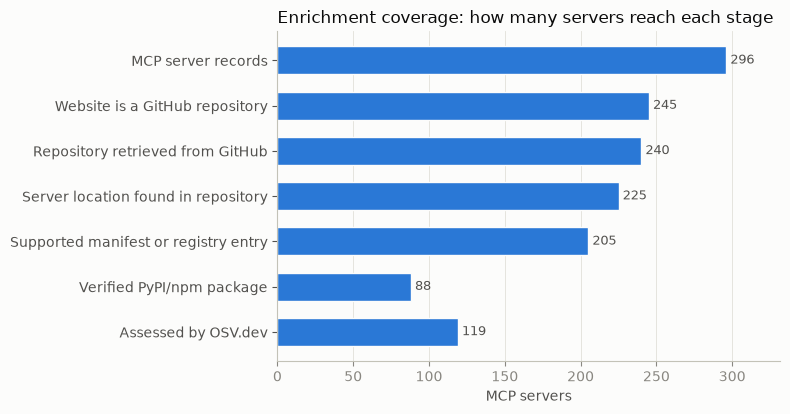

In [29]:
coverage = pd.Series({
    "MCP server records": len(enriched),
    "Website is a GitHub repository": int(enriched["repository_id"].notna().sum()),
    "Repository retrieved from GitHub": int((enriched["repository_lookup_status"] == "found").sum()),
    "Server location found in repository": int((enriched["github_status"] == "mapped").sum()),
    "Supported manifest or registry entry": int((enriched["manifest_files"].notna() | (enriched["registry_match_status"] == "matched")).sum()),
    "Verified PyPI/npm package": int(enriched["package_mapping_status"].fillna("").str.contains("verified").sum()),
    "Assessed by OSV.dev": int((enriched["assessment_scope"] != "none").sum()),
})
horizontal_bars(coverage, "Enrichment coverage: how many servers reach each stage", "MCP servers")

**Interpretation.** The coverage chart shows where records drop out of the enrichment process. The largest loss happens at the very first step, because some records point to product websites instead of code repositories. The next losses come from repository locations that no longer exist (stale monorepo subdirectories), repositories without a supported Python/JavaScript manifest (for example Go, Rust, or Java projects), and packages whose identity could not be verified. The last bar can be larger than the one above it because a server without a verified package can still be assessed through its exactly pinned dependencies.

In [30]:
manifests = pd.read_csv(STAGING / "server_repository_map.csv")
unsupported = manifests[manifests["manifest_files"].isna() & manifests["unsupported_manifest_files"].notna()]
unsupported["unsupported_manifest_files"].str.split("; ").explode().value_counts().rename("servers").to_frame()

,servers
unsupported_manifest_files,
go.mod,7
Cargo.toml,3
pom.xml,2


## 11. PyPI and npm enrichment results

Package identity was **not guessed from names**. A package is accepted as a server's package (`verified`) in two cases:

1. the server's own Official MCP Registry entry lists the package (the registry checks that the publisher controls it), or
2. a manifest at the server's repository location (`package.json` with a `name` and without `"private": true`, `pyproject.toml`, or `setup.cfg`) declares the name **and** the registry metadata links back to the same GitHub repository.

Packages that exist on the registry but do not link back are `ambiguous`, and names that are not on the registry are `not_published`.

In [31]:
server_packages = pd.read_csv(STAGING / "server_package_map.csv")
packages = pd.read_csv(STAGING / "packages.csv")
display(pd.crosstab([server_packages["candidate_source"], server_packages["mapping_status"]], server_packages["ecosystem"], margins=True))
server_packages.loc[server_packages["mapping_status"] == "verified", ["server_id", "package_id", "candidate_source", "mapping_evidence", "identified_version", "version_source"]].head(10)

ecosystem                             PyPI  npm  All
candidate_source      mapping_status                
official_mcp_registry verified           6    7   13
repository_manifest   ambiguous         38   40   78
                      not_published     17    9   26
                      verified          27   49   76
All                                     88  105  193

,server_id,package_id,candidate_source,mapping_evidence,identified_version,version_source
0,deepnlp:pub-firecrawl,npm:firecrawl-mcp,official_mcp_registry,official_mcp_registry_lists_package,3.30.3,official_mcp_registry
1,deepnlp:pub-excel,PyPI:excel-mcp-server,official_mcp_registry,official_mcp_registry_lists_package,2.1.1,official_mcp_registry
2,deepnlp:pub-motherduck,PyPI:mcp-server-motherduck,official_mcp_registry,official_mcp_registry_lists_package,1.1.0,official_mcp_registry
3,deepnlp:pub-keboola,PyPI:keboola-mcp-server,official_mcp_registry,official_mcp_registry_lists_package,1.95.3,official_mcp_registry
4,deepnlp:pub-elasticsearch,PyPI:elasticsearch-mcp-server,official_mcp_registry,official_mcp_registry_lists_package,2.0.15,official_mcp_registry
5,deepnlp:pub-deepseek-mcp-server,npm:deepseek-mcp-server,official_mcp_registry,official_mcp_registry_lists_package,0.3.1,official_mcp_registry
6,deepnlp:pub-figma,npm:figma-developer-mcp,official_mcp_registry,official_mcp_registry_lists_package,0.13.2,official_mcp_registry
7,deepnlp:pub-kubernetes-and-openshift,npm:kubernetes-mcp-server,official_mcp_registry,official_mcp_registry_lists_package,0.0.67,official_mcp_registry
8,deepnlp:pub-kubernetes-and-openshift,PyPI:kubernetes-mcp-server,official_mcp_registry,official_mcp_registry_lists_package,0.0.67,official_mcp_registry
9,deepnlp:pub-searxng,npm:mcp-searxng,official_mcp_registry,official_mcp_registry_lists_package,2.6.0,official_mcp_registry


In [32]:
ambiguous = server_packages[server_packages["mapping_status"] == "ambiguous"].merge(packages[["package_id", "registry_repository_ids"]], on="package_id")
ambiguous = ambiguous.merge(servers[["server_id", "repository_id"]], on="server_id")
ambiguous[["server_id", "package_id", "repository_id", "registry_repository_ids"]].head(10)

,server_id,package_id,repository_id,registry_repository_ids
0,deepnlp:pub-milvus,PyPI:mcp-server-milvus,github:zilliztech/mcp-server-milvus,github:danchev/mcp-server-milvus
1,deepnlp:pub-discord,npm:discord-mcp-server,github:v-3/discordmcp,NaN
2,deepnlp:pub-atlassian,PyPI:mcp-atlassian,github:sooperset/mcp-atlassian,NaN
3,deepnlp:pub-snowflake,PyPI:mcp-snowflake-server,github:isaacwasserman/mcp-snowflake-server,NaN
4,deepnlp:pub-cryptopanic-mcp-server,PyPI:cryptopanic-mcp-server,github:kukapay/cryptopanic-mcp-server,NaN
5,deepnlp:pub-webflow,npm:webflow-mcp-server,github:kapilduraphe/webflow-mcp-server,NaN
6,deepnlp:pub-placid-app,npm:@felores/placid-mcp-server,github:felores/placid-mcp-server,NaN
7,deepnlp:pub-pandoc,PyPI:mcp-pandoc,github:vivekvells/mcp-pandoc,NaN
8,deepnlp:pub-rememberizer-ai,PyPI:mcp-server-rememberizer,github:skydeckai/mcp-server-rememberizer,NaN
9,deepnlp:pub-gmail-headless,npm:@peakmojo/mcp-server-headless-gmail,github:baryhuang/mcp-headless-gmail,NaN


The ambiguous examples show why the back-link rule matters: in several cases the name declared in the repository belongs to a *different* project on the registry, or the registry entry gives no repository at all. Linking these packages to the server would have created false relationships and possibly false vulnerability findings.

Package names and versions were also validated against PyPI and npm rules, as our report proposed for invalid values:

In [33]:
server_packages[["declared_name_is_valid", "declared_version_is_valid", "declared_version_is_published"]].apply(lambda column: column.value_counts()).fillna(0).astype(int)

,declared_name_is_valid,declared_version_is_valid,declared_version_is_published
False,0,3,49
True,193,190,144


### 11.1 Dependency analysis

Declared dependencies come from the manifests. Most use version ranges (for example `>=1.0.0` or `^3.24.1`), so the version actually installed is unknown. deps.dev fills this gap for verified packages: it returns the resolved dependency graph of a package version, with direct and indirect dependencies and their exact versions.

In [34]:
dependencies = pd.read_csv(STAGING / "dependencies.csv")
resolved = pd.read_csv(STAGING / "resolved_dependencies.csv")
dependency_overview = pd.DataFrame({
    "declared_rows": dependencies.groupby("ecosystem").size(),
    "pinned_rows": dependencies.dropna(subset=["pinned_version"]).groupby("ecosystem").size(),
    "unique_declared": dependencies.dropna(subset=["dependency_name"]).drop_duplicates(["ecosystem", "dependency_name"]).groupby("ecosystem").size(),
    "resolved_rows": resolved.groupby("ecosystem").size(),
}).fillna(0).astype(int)
display(dependency_overview)
display(server_packages["dependency_graph_status"].value_counts().rename("package versions").to_frame())
resolved["relation"].value_counts().rename("resolved dependencies").to_frame()

,declared_rows,pinned_rows,unique_declared,resolved_rows
ecosystem,,,,
PyPI,671,122,251,1762
npm,531,80,220,6199


,package versions
dependency_graph_status,
found,87
not_found,2


,resolved dependencies
relation,
indirect,7473
direct,488


## 12. OSV.dev vulnerability analysis

OSV.dev was queried with `/v1/querybatch` for every unique (ecosystem, package, version) combination coming from verified server packages, manifest dependencies pinned to an exact version, and deps.dev-resolved dependencies. The full record for every returned vulnerability was then downloaded from `/v1/vulns/<id>`. Each lookup keeps an explicit status so that "not checked" is never confused with "no vulnerabilities".

In [35]:
enrichment = pd.read_csv(REPORTS / "enrichment_summary.csv")
enrichment[enrichment["area"] == "osv"]

,area,metric,value,denominator,pct
75,osv,osv_targets_queried,1818,NaN,NaN
76,osv,osv_queries_completed,1818,1818.0,100.00
77,osv,osv_queries_failed,0,1818.0,0.00
78,osv,osv_targets_with_known_vulnerabilities,80,1818.0,4.40
79,osv,osv_targets_with_no_known_vulnerabilities,1738,1818.0,95.60
80,osv,package_rows_skipped,104,193.0,53.89
81,osv,dependency_rows_skipped_unknown_version,1000,1202.0,83.19
82,osv,resolved_dependency_rows_with_known_vulnerabilities,68,7961.0,0.85
83,osv,unique_osv_vulnerability_records,292,NaN,NaN
84,osv,unique_vulnerabilities_after_alias_grouping,174,NaN,NaN


In [36]:
vulnerabilities = pd.read_csv(STAGING / "vulnerabilities.csv")
package_vulnerabilities = pd.read_csv(STAGING / "package_vulnerability_map.csv")
print("OSV vulnerability records:", len(vulnerabilities))
print("Unique vulnerabilities after alias grouping:", vulnerabilities["vulnerability_group_id"].nunique())
print("Records with at least one CVE alias:", int(vulnerabilities["cve_ids"].notna().sum()))
display(vulnerabilities.drop_duplicates("vulnerability_group_id")["severity_label"].fillna("(not provided)").value_counts().rename("vulnerabilities").to_frame())
grouped = vulnerabilities.groupby("vulnerability_group_id").filter(lambda group: len(group) > 1)
grouped[["vulnerability_group_id", "vulnerability_id", "aliases"]].head(6)

OSV vulnerability records: 292
Unique vulnerabilities after alias grouping: 174
Records with at least one CVE alias: 282


,vulnerabilities
severity_label,
MODERATE,69
HIGH,58
LOW,27
(not provided),13
CRITICAL,7


,vulnerability_group_id,vulnerability_id,aliases
0,GHSA-29pf-2h5f-8g72,GHSA-29pf-2h5f-8g72,CVE-2026-4372; PYSEC-2026-2289
1,GHSA-2c2j-9gv5-cj73,GHSA-2c2j-9gv5-cj73,CVE-2025-54121; PYSEC-2026-1941
2,GHSA-2fqr-mr3j-6wp8,GHSA-2fqr-mr3j-6wp8,CVE-2026-54279; PYSEC-2026-2112
4,GHSA-2vrm-gr82-f7m5,GHSA-2vrm-gr82-f7m5,CVE-2026-34514; PYSEC-2026-2096
5,GHSA-2wm9-hf6c-p5cr,GHSA-2wm9-hf6c-p5cr,CVE-2026-45830; PYSEC-2026-3813
6,GHSA-2xpw-w6gg-jr37,GHSA-2xpw-w6gg-jr37,CVE-2025-66471; PYSEC-2026-1994


The last table shows why alias grouping is needed: the same vulnerability is often published both as a GitHub advisory (`GHSA-...`) and as a Python advisory (`PYSEC-...`), and OSV returns both. Counting distinct `vulnerability_group_id` values instead of OSV ids avoids counting one vulnerability twice.

In [37]:
top_versions = package_vulnerabilities.groupby(["ecosystem", "package_name", "package_version"])["vulnerability_group_id"].nunique()
display(top_versions.sort_values(ascending=False).head(10).rename("unique_vulnerabilities").to_frame())
affected = enriched[enriched["known_vulnerability_count"].fillna(0) > 0]
affected[["server_name", "repository_full_name", "package_vulnerability_status", "pinned_dependency_count", "resolved_dependency_count", "vulnerable_dependency_count", "known_vulnerability_count"]].sort_values("known_vulnerability_count", ascending=False).head(15)

unique_vulnerabilities
ecosystem package_name package_version                        
PyPI      aiohttp      3.8.5                                42
                       3.11.11                              33
                       3.11.15                              33
          pillow       10.4.0                               17
          transformers 4.53.3                               13
npm       undici       5.29.0                               13
PyPI      urllib3      2.4.0                                 8
          fastmcp      2.8.0                                 8
          starlette    0.45.2                                7
                       0.46.2                                7

,server_name,repository_full_name,package_vulnerability_status,pinned_dependency_count,resolved_dependency_count,vulnerable_dependency_count,known_vulnerability_count
89,Open Strategy Partners Marketing Tools,open-strategy-partners/osp_marketing_tools,unknown_package_identity,26,0,8,51.0
79,Heurist Mesh network,heurist-network/heurist-agent-framework,ambiguous_mapping,22,0,5,46.0
124,LINE,amornpan/py-mcp-line,unknown_package_identity,6,0,4,45.0
182,Rquest,xxxbrian/mcp-rquest,no_known_vulnerabilities_found,0,124,3,31.0
13,Playwright,executeautomation/mcp-playwright,no_known_vulnerabilities_found,6,299,11,26.0
154,MySQL,benborla/mcp-server-mysql,no_known_vulnerabilities_found,1,195,6,23.0
61,VolcEngine TOS,dinghuazhou/sample-mcp-server-tos,unknown_package_identity,34,0,7,22.0
78,X (Twitter),EnesCinr/twitter-mcp,no_known_vulnerabilities_found,1,191,6,20.0
51,Browserbase,browserbase/mcp-server-browserbase,known_vulnerabilities_found,0,233,2,16.0
229,iFlytek Workflow,iflytek/ifly-workflow-mcp-server,unknown_package_identity,7,0,5,15.0


Each server has two vulnerability statuses: one for its own package (`package_vulnerability_status`) and an overall status that also includes its dependencies (`vulnerability_assessment_status`). `assessment_scope` records which parts were actually checked.

In [38]:
display(enriched["package_vulnerability_status"].value_counts().rename("servers").to_frame())
enriched["assessment_scope"].value_counts().rename("servers").to_frame()

,servers
package_vulnerability_status,
no_known_vulnerabilities_found,87
ambiguous_mapping,76
not_assessed,71
unknown_package_identity,61
known_vulnerabilities_found,1


,servers
assessment_scope,
none,177
package_and_dependencies,83
dependencies_only,31
package_only,5


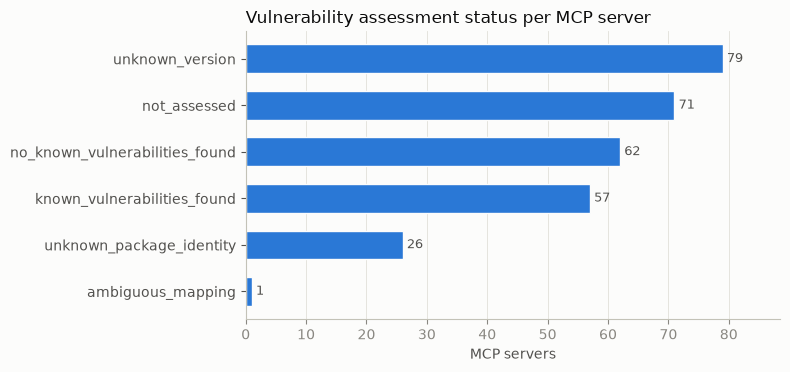

In [39]:
status_counts = enriched["vulnerability_assessment_status"].value_counts()
horizontal_bars(status_counts, "Vulnerability assessment status per MCP server", "MCP servers")

**Interpretation.** Only the statuses `known_vulnerabilities_found` and `no_known_vulnerabilities_found` mean that OSV.dev was actually queried. All other statuses describe *why* a server could not be assessed: the record has no repository (`not_assessed`), no reliable package could be identified (`unknown_package_identity`), the package mapping was not trustworthy (`ambiguous_mapping`), or the dependencies only have version ranges (`unknown_version`). These servers must not be treated as secure. In the processed dataset their `known_vulnerability_count` is empty rather than zero.

## 13. Before/after quality comparison (DeepNLP)

In [40]:
before_profile = before.set_index("column")
after_profile = after.set_index("column")
duplicates = pd.read_csv(REPORTS / "duplicate_summary.csv").query("dataset == 'deepnlp'").set_index("check")["count"]
issues = pd.read_csv(REPORTS / "data_quality_issues.csv").query("dataset == 'deepnlp'").set_index("issue")["affected_records"]
pd.DataFrame([
    {"measure": "Records", "before": len(raw_frame), "after": len(servers)},
    {"measure": "Source attributes / staging columns", "before": raw_frame.shape[1], "after": servers.shape[1]},
    {"measure": "Blank or placeholder strings (cleaned columns)", "before": int(before_profile["blank_or_placeholder_count"].sum()), "after": int(after_profile.loc[~after_profile.index.str.endswith("_original"), "blank_or_placeholder_count"].sum())},
    {"measure": "Columns that are 100% empty", "before": int((before_profile["missing_pct"] == 100).sum()), "after": int((after_profile["missing_pct"] == 100).sum())},
    {"measure": "Descriptions with surrounding whitespace", "before": int(issues["description_surrounding_whitespace"]), "after": int((servers["description"].dropna() != servers["description"].dropna().str.strip()).sum())},
    {"measure": "Descriptions starting with a list marker", "before": int(issues["description_starts_with_list_marker"]), "after": int(servers["description"].dropna().str.match(r"^\s*[-–—:]").sum())},
    {"measure": "Websites with trailing slash / fragment", "before": int(issues["website_trailing_slash"] + issues["website_url_fragment"]), "after": int(servers["website_normalized"].str.contains(r"/$|#", regex=True).sum())},
    {"measure": "Month stored as YYYYMM text", "before": int(issues["month_stored_as_yyyymm_text"]), "after": int(servers["snapshot_month"].astype(str).str.fullmatch(r"\d{6}").sum())},
    {"measure": "Exact duplicate records", "before": int(duplicates["exact_duplicate_records"]), "after": int(servers.drop(columns=["server_id", "source_record_number"]).duplicated().sum())},
    {"measure": "Records with a parsed repository_id", "before": 0, "after": int(servers["repository_id"].notna().sum())},
])

,measure,before,after
0,Records,296,296
1,Source attributes / staging columns,11,29
2,Blank or placeholder strings (cleaned columns),297,0
3,Columns that are 100% empty,1,0
4,Descriptions with surrounding whitespace,250,0
5,Descriptions starting with a list marker,222,0
6,Websites with trailing slash / fragment,28,0
7,Month stored as YYYYMM text,296,0
8,Exact duplicate records,0,0
9,Records with a parsed repository_id,0,245


Every format problem that was measured before cleaning is gone in the cleaned columns. The two traceability columns `website_original` and `description_original` deliberately keep the raw values (including one raw description that is an empty string), so they are excluded from the "after" count of blank strings. The number of columns grows from 11 to 29 because cleaning *adds* normalized and flag columns instead of overwriting the originals.

## 14. Final processed dataset

The pipeline exported fourteen normalized staging tables and one denormalized processed table. Column definitions, candidate primary keys, and foreign keys are documented in `docs/data_dictionary.md`.

In [41]:
outputs = []
for path in sorted(STAGING.glob("*.csv")) + sorted(PROCESSED.glob("*.csv")):
    frame = pd.read_csv(path, low_memory=False)
    outputs.append({"file": str(path.relative_to(PROJECT_ROOT)), "rows": len(frame), "columns": frame.shape[1]})
pd.DataFrame(outputs)

,file,rows,columns
0,data/staging/dependencies.csv,1202,13
1,data/staging/documents.csv,2230,14
2,data/staging/mcp_registry_packages.csv,19358,12
3,data/staging/mcp_registry_servers.csv,45657,17
4,data/staging/mcp_servers.csv,296,29
5,data/staging/mcpcorpus_servers.csv,13873,34
6,data/staging/package_vulnerability_map.csv,532,8
7,data/staging/packages.csv,193,13
8,data/staging/repositories.csv,227,32
9,data/staging/resolved_dependencies.csv,7961,12


Before handing the files to Sprint 2 we validated the relationships between them. Each check below should be `True`. A failing check would mean that a key is not unique, that a foreign key points to a missing row, or that a vulnerability count was reported for a lookup that never succeeded.

In [42]:
server_repository_map = pd.read_csv(STAGING / "server_repository_map.csv")
registry = pd.read_csv(STAGING / "mcp_registry_servers.csv", low_memory=False)
assessed = {"known_vulnerabilities_found", "no_known_vulnerabilities_found"}
verified_keys = set(zip(server_packages["ecosystem"], server_packages["package_name"], server_packages["identified_version"]))
checks = {
    "server_id is unique in mcp_servers": servers["server_id"].is_unique,
    "repository_id is unique in repositories": repositories["repository_id"].is_unique,
    "package_id is unique in packages": packages["package_id"].is_unique,
    "vulnerability_id is unique in vulnerabilities": vulnerabilities["vulnerability_id"].is_unique,
    "document_id is unique in documents": documents["document_id"].is_unique,
    "registry_name is unique in mcp_registry_servers": registry["registry_name"].is_unique,
    "corpus_id is unique in mcpcorpus_servers": corpus["corpus_id"].is_unique,
    "(registry_name, package_position) is unique in mcp_registry_packages": not registry_packages.duplicated(["registry_name", "package_position"]).any(),
    "every registry package belongs to a registry entry": registry_packages["registry_name"].isin(registry["registry_name"]).all(),
    "every mapped repository_id exists in repositories": server_repository_map["repository_id"].isin(repositories["repository_id"]).all(),
    "every map server_id exists in mcp_servers": server_repository_map["server_id"].isin(servers["server_id"]).all(),
    "every server_package_map package_id exists in packages": server_packages["package_id"].isin(packages["package_id"]).all(),
    "every dependency server_id exists in mcp_servers": dependencies["server_id"].isin(servers["server_id"]).all(),
    "every resolved graph belongs to a verified package version": all(key in verified_keys for key in zip(resolved["ecosystem"], resolved["package_name"], resolved["package_version"])),
    "every document repository_id exists in repositories": documents["repository_id"].dropna().isin(repositories["repository_id"]).all(),
    "every linked registry record exists": server_source_map.query("linked_source == 'official_mcp_registry'")["linked_record_id"].isin(registry["registry_name"]).all(),
    "every linked corpus record exists": server_source_map.query("linked_source == 'mcpcorpus'")["linked_record_id"].isin(corpus["corpus_id"]).all(),
    "every matched vulnerability_id exists in vulnerabilities": package_vulnerabilities["vulnerability_id"].isin(vulnerabilities["vulnerability_id"]).all(),
    "processed table has one row per server": len(enriched) == len(servers) and enriched["server_id"].is_unique,
    "no zero vulnerability count without a successful lookup": enriched.loc[enriched["assessment_scope"] == "none", "known_vulnerability_count"].isna().all(),
    "package rows have a count only when assessed": (server_packages["known_vulnerability_count"].notna() == server_packages["osv_status"].isin(assessed)).all(),
    "dependency rows have a count only when assessed": (dependencies["known_vulnerability_count"].notna() == dependencies["osv_status"].isin(assessed)).all(),
    "resolved rows have a count only when assessed": (resolved["known_vulnerability_count"].notna() == resolved["osv_status"].isin(assessed)).all(),
}
pd.Series(checks, name="passed").to_frame()

,passed
server_id is unique in mcp_servers,True
repository_id is unique in repositories,True
package_id is unique in packages,True
vulnerability_id is unique in vulnerabilities,True
document_id is unique in documents,True
registry_name is unique in mcp_registry_servers,True
corpus_id is unique in mcpcorpus_servers,True
"(registry_name, package_position) is unique in mcp_registry_packages",True
every registry package belongs to a registry entry,True
every mapped repository_id exists in repositories,True


In [43]:
enriched[[
    "server_id", "server_name", "github_status", "registry_match_status", "corpus_category", "stars", "days_since_last_commit",
    "package_ids", "package_mapping_status", "identified_versions", "resolved_dependency_count",
    "vulnerability_assessment_status", "known_vulnerability_count",
]].head(12)

,server_id,server_name,github_status,registry_match_status,corpus_category,stars,days_since_last_commit,package_ids,package_mapping_status,identified_versions,resolved_dependency_count,vulnerability_assessment_status,known_vulnerability_count
0,deepnlp:pub-agentrpc,AgentRPC,not_github,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_assessed,NaN
1,deepnlp:pub-git,Git,mapped,NaN,NaN,91338.0,7.0,PyPI:mcp-server-git,verified,2026.10.10,32,no_known_vulnerabilities_found,0.0
2,deepnlp:pub-actors-mcp-server,Actors MCP Server,not_github,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_assessed,NaN
3,deepnlp:pub-arangodb,ArangoDB,not_github,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_assessed,NaN
4,deepnlp:pub-anki,Anki,not_github,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_assessed,NaN
5,deepnlp:pub-descope,Descope,not_github,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_assessed,NaN
6,deepnlp:pub-aws-kb-retrieval,AWS KB Retrieval,subpath_not_found,NaN,research-and-data,91338.0,7.0,NaN,NaN,NaN,0,not_assessed,NaN
7,deepnlp:pub-lingo-dev,Lingo.dev,not_github,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_assessed,NaN
8,deepnlp:pub-openrpc,OpenRPC,not_github,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_assessed,NaN
9,deepnlp:pub-apimatic,APIMatic,not_github,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_assessed,NaN


In [44]:
key_metrics = enrichment.set_index("metric")
key_metrics.loc[[
    "mcp_server_records", "mcp_registry_servers", "mcpcorpus_records_retained", "servers_matched_in_mcp_registry",
    "servers_matched_in_mcpcorpus", "repository_lookups_succeeded", "documents_kept_after_filtering",
    "servers_with_verified_package", "mappings_verified_by_mcp_registry", "unique_resolved_dependency_versions",
    "osv_queries_completed", "osv_queries_failed", "unique_vulnerabilities_after_alias_grouping",
    "servers_with_known_vulnerabilities", "servers_not_assessed_for_vulnerabilities",
], ["value", "denominator", "pct"]]

,value,denominator,pct
metric,,,
mcp_server_records,296,NaN,NaN
mcp_registry_servers,45657,NaN,NaN
mcpcorpus_records_retained,13873,NaN,NaN
servers_matched_in_mcp_registry,18,296.0,6.08
servers_matched_in_mcpcorpus,166,296.0,56.08
repository_lookups_succeeded,222,227.0,97.80
documents_kept_after_filtering,945,2230.0,42.38
servers_with_verified_package,88,296.0,29.73
mappings_verified_by_mcp_registry,13,89.0,14.61


## 15. Findings and observations

The numbers below come from our full pipeline run on 18 October 2026 and match the key-metrics table directly above. If the pipeline is run again after clearing `data/cache/`, the live API counts (repositories, packages, vulnerabilities) can change slightly, but the DeepNLP, MCP Registry, and MCPCorpus profiles stay the same because the raw snapshots are kept in `data/raw/`.

**1. The DeepNLP dataset is a usable inventory but a weak source of attributes.** All 296 records have a name, a publisher id, and a website, and there are no exact or identifier-level duplicates. However, `field`, `subfield`, and `month` are constant, `content` is empty in every record, and the only nested statistic (`Bing Rank`) exists in just 50 records (83.11% missing). DeepNLP tells us *which* servers exist, not *how* they differ, so almost all security-relevant information had to come from the other sources.

**2. The main DeepNLP quality problem is text, not missing identifiers.** 222 descriptions (75%) start with a markdown list marker and 250 (84.46%) have surrounding whitespace, which shows the data was scraped from a markdown "awesome list". After cleaning, 43 descriptions (14.53%) are still flagged: 21 fragments, 9 empty, 8 website boilerplate, and 5 too short. We kept and flagged these records instead of deleting them.

**3. Roughly one in six DeepNLP records cannot be connected to code.** 50 records (16.89%) point to a product or marketing website instead of a repository, and 1 record points to a GitHub organization. Linking these to a package would require guessing, so they are marked `not_assessed`.

**4. The three inventories overlap much less than expected, which makes entity resolution essential.** The Official MCP Registry has 45,657 servers, but only 29 of its entries point to any of our 227 repositories; 18 DeepNLP servers match exactly one registry entry and 3 match several (for example a server listed both by its owner and as a Smithery re-publication). MCPCorpus covers more of DeepNLP: 166 servers match exactly one corpus record and 27 match several, because the corpus lists 471 repository locations more than once (1,007 records). Inside DeepNLP, the `modelcontextprotocol/servers` monorepo hosts 19 separate servers, so "same repository" never means "same server".

**5. Category data exists only in MCPCorpus, and it is heavily imbalanced.** Through the corpus link, 182 DeepNLP servers now have a category (mostly `developer-tools` with 101 and `research-and-data` with 61). Across the whole corpus the two largest categories hold 86.12% of all records, while 7 categories have fewer than ten records. This is the data imbalance our report expected, and it would need to be handled before any category-based model.

**6. Many repositories are stale or maintained by very few people.** 222 of 227 repositories (97.8%) were retrieved, but 5 no longer exist, 21 have moved, 19 are archived, and 15 servers point to a monorepo subdirectory that has been removed. The median repository's last commit was 310 days before collection, 103 repositories (46.4%) have not had a commit in over a year, the median repository has only 4 contributors (29 have a single contributor), and only 100 (45%) have ever published a GitHub release.

**7. Reliable package identity is still the biggest bottleneck, and the MCP Registry helps.** 193 package candidates were found (180 from manifests, 13 from MCP Registry entries). 89 were verified, 13 of them because the server's registry entry lists the package; several of these (for example `keboola-mcp-server` and `mcp-server-motherduck`) had been ambiguous before because their PyPI page has no repository link. 78 candidates remain ambiguous and 26 are not published. In total only 88 of 296 servers (29.73%) have a verified PyPI or npm package. Version validation found that 49 declared versions (25.39%) do not exist on the registry.

**8. deps.dev turns unknown dependency versions into checkable ones.** The manifests declare 1,202 dependencies (471 unique), but only 202 (16.81%) pin an exact version. deps.dev returned a resolved dependency graph for 87 of the 89 verified package versions, adding 7,961 resolved dependency rows (1,626 unique dependency versions, 94% of them indirect). Without deps.dev, transitive dependencies would have been invisible.

**9. Known vulnerabilities come almost entirely from dependencies.** All 1,818 OSV.dev queries completed and 80 package versions have known vulnerabilities. OSV returned 292 records, which reduce to 174 unique vulnerabilities after alias grouping (7 critical, 58 high, 69 moderate, 27 low, 13 without a label). 57 servers (19.26%) have at least one known vulnerability: 45 through a pinned manifest dependency, 28 through a deps.dev-resolved dependency (11 of them were found *only* through deps.dev), and just 1 through the server's own package. The most affected versions are `aiohttp` 3.8.5 (42 vulnerabilities), `pillow` 10.4.0 (17), and `transformers` 4.53.3 and `undici` 5.29.0 (13 each). A fixed version is listed for 93.2% of the matches.

**10. "Unknown" is still the largest outcome, and it is not the same as "safe".** Only 119 servers (40.20%) could be assessed by OSV.dev, and 62 of them have no known vulnerabilities in what we could check. The other 177 servers (59.80%) could not be assessed because their dependency versions are unknown, they have no repository, their package is ambiguous, or no package could be identified. A risk score in a later sprint must treat missing evidence as uncertainty, not as low risk.

**11. The text corpus is now real and traceable.** The pipeline collected 2,230 GitHub documents and kept 945 after filtering: 224 READMEs, 93 release notes, and 628 issues. Filtering mattered: 1,258 of the items returned by the issues endpoint were pull requests. The median kept README has about 610 words. Every document carries its server or repository id, URL, and collection time, as our report required.

**12. The MCP Registry adds security metadata we did not have before.** 7,069 registry packages (36.52%) declare at least one secret environment variable (an API key or token). Our report listed credential handling as missing information, so this is a useful starting point for later sprints.

## 16. Limitations

- **Snapshot age.** DeepNLP (March 2025) and MCPCorpus (September 2025 commit) are snapshots, while the MCP Registry, GitHub, the package registries, deps.dev, and OSV.dev were queried live. Some references have become stale (moved repositories, deleted monorepo subdirectories), and there is no history yet for change detection.
- **Non-repository websites.** DeepNLP records whose website is a product page cannot be linked to a repository or package without guessing, so they are retained but not assessed.
- **Depth of enrichment.** Only the DeepNLP servers were enriched in depth. The MCP Registry and MCPCorpus were profiled and linked, but enriching their tens of thousands of servers one by one would need far more API requests than Sprint 1 allows.
- **Manifest coverage.** Only `package.json`, `pyproject.toml`, `setup.cfg`, and `requirements.txt` at the server's own location are parsed. `setup.py` is not executed, lock files are not read, and Go, Rust, Java, and other ecosystems are only detected.
- **Resolved versions.** deps.dev resolves version ranges the way a fresh install would today; it does not tell us what an existing user has installed.
- **Heuristic flags and text cleaning.** The description quality, generic name, and semantic duplicate flags and the markdown cleaning rules are simple heuristics; they are flags for review, not automatic deletions.
- **Vulnerability scope.** OSV.dev covers publicly disclosed package vulnerabilities only. MCP-specific risks such as tool poisoning, excessive permissions, or missing authentication are not measured yet.
- **Live data.** API data changes over time. Every row records `collected_at`, and responses are cached in `data/cache/` so a rerun reproduces the same results until the cache is cleared.

## 17. Sprint 2 preparation

The staging tables are ready to become PostgreSQL tables:

| Table | Primary key | Foreign keys |
|---|---|---|
| `mcp_servers` | `server_id` | `repository_id` → `repositories` |
| `repositories` | `repository_id` | — |
| `server_repository_map` | `server_id` | `server_id` → `mcp_servers`, `repository_id` → `repositories` |
| `documents` | `document_id` | `server_id` → `mcp_servers`, `repository_id` → `repositories` |
| `mcp_registry_servers` | `registry_name` | — |
| `mcp_registry_packages` | (`registry_name`, `package_position`) | `registry_name` → `mcp_registry_servers` |
| `mcpcorpus_servers` | `corpus_id` | — |
| `server_source_map` | (`server_id`, `linked_source`, `linked_record_id`) | `server_id` → `mcp_servers` |
| `packages` | `package_id` | — |
| `server_package_map` | (`server_id`, `package_id`) | `server_id` → `mcp_servers`, `package_id` → `packages` |
| `dependencies` | `dependency_id` | `server_id` → `mcp_servers` |
| `resolved_dependencies` | (`ecosystem`, `package_name`, `package_version`, `dependency_ecosystem`, `dependency_name`, `dependency_version`) | package version → `server_package_map` |
| `vulnerabilities` | `vulnerability_id` | — |
| `package_vulnerability_map` | (`ecosystem`, `package_name`, `package_version`, `vulnerability_id`) | `vulnerability_id` → `vulnerabilities` |

Planned Sprint 2 work:

1. Create the PostgreSQL schema with these keys and load the CSV files with `COPY`.
2. Store raw API responses as `jsonb` next to the normalized tables, as proposed in the original Sprint 1 report.
3. Add a `scan_id` and scan timestamp so that repeated runs become scan history instead of overwriting earlier results.
4. Derive the security features from our feature dictionary (`known_vulnerability_count`, `vulnerable_dependency_count`, `days_since_last_commit`, `repository_archived`, `dependency_count`) and start the rule-based risk score.
5. Extend enrichment to the MCP Registry and MCPCorpus servers, parse lock files, and support more ecosystems.